In [1]:
import extraction_classification as ec
import pandas as pd
tumor = "COAD"

In [2]:
import pandas as pd

# 2. Load the normal and cancer matrices from the Preprocessing stage
# Note: The preprocessing script saved them with a semicolon separator (sep=';')
normal = pd.read_csv('./Matrices/normal_' + str(tumor) + '.csv', sep=';', index_col=0)
cancer = pd.read_csv('./Matrices/cancer_' + str(tumor) + '.csv', sep=';', index_col=0)

print("Matrices loaded successfully! Normal shape:", normal.shape, "Cancer shape:", cancer.shape)

Matrices loaded successfully! Normal shape: (18771, 8) Cancer shape: (18771, 452)


In [3]:
#After having saved the communities with gephi and having saved the indices of them
#We extract the ensembl and the relative expressions
communities = pd.read_csv('./Extracted/comm_'+str(tumor)+'.csv', sep=',')
communities_genes = normal.index[communities['Id']]
pd.DataFrame(communities_genes).to_csv('./Extracted/IC_genes_'+str(tumor)+'.csv')

In [4]:
comm_genes_norm=pd.DataFrame(index=communities_genes, columns=normal.columns)
comm_genes_canc=pd.DataFrame(index=communities_genes, columns=cancer.columns)

In [5]:
def extract_communities(A, A_norm, A_canc, N, C):
    for i in N.index:
        for j in A:
            if i==j:
                A_norm[A_norm.index==j]=(N[N.index==i].values)
     
    for i in C.index:
        for j in A:
            if i==j:
                A_canc[A_canc.index==j]=(C[C.index==i].values)
                
    return A_norm, A_canc

comm_genes_norm, comm_genes_canc = extract_communities(communities_genes, comm_genes_norm, comm_genes_canc, normal, cancer)
comm_genes_norm.to_csv('./Extracted/exp_IC_norm'+str(tumor)+'.csv')
comm_genes_canc.to_csv('./Extracted/exp_IC_canc'+str(tumor)+'.csv')

In [6]:
#We load the expressions of DE genes found with t-test statistic
de_norm = pd.read_csv('./Extracted/exp_de_norm'+str(tumor)+'.csv', index_col=0, header=0)
de_canc = pd.read_csv('./Extracted/exp_de_canc'+str(tumor)+'.csv', index_col=0, header=0)

In [8]:
#We compute the computational validation of the genes extracted (integrated communities genes (IC), DE and Random)
#All details are in extraction_classification.py script
rf = ec.RF(normal, cancer, comm_genes_norm, comm_genes_canc, de_norm, de_canc, str(tumor))

100%|█████████████████████████████████████████████████████████████████████████████| 100/100 [3:44:11<00:00, 134.51s/it]


In [12]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FormatStrFormatter

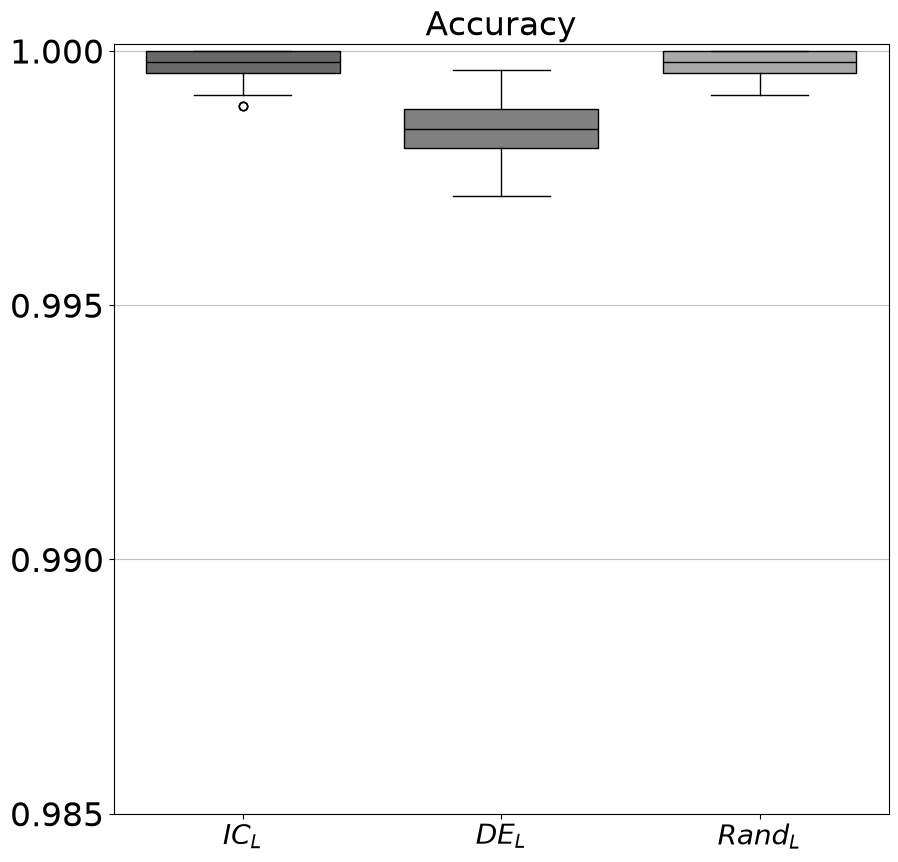

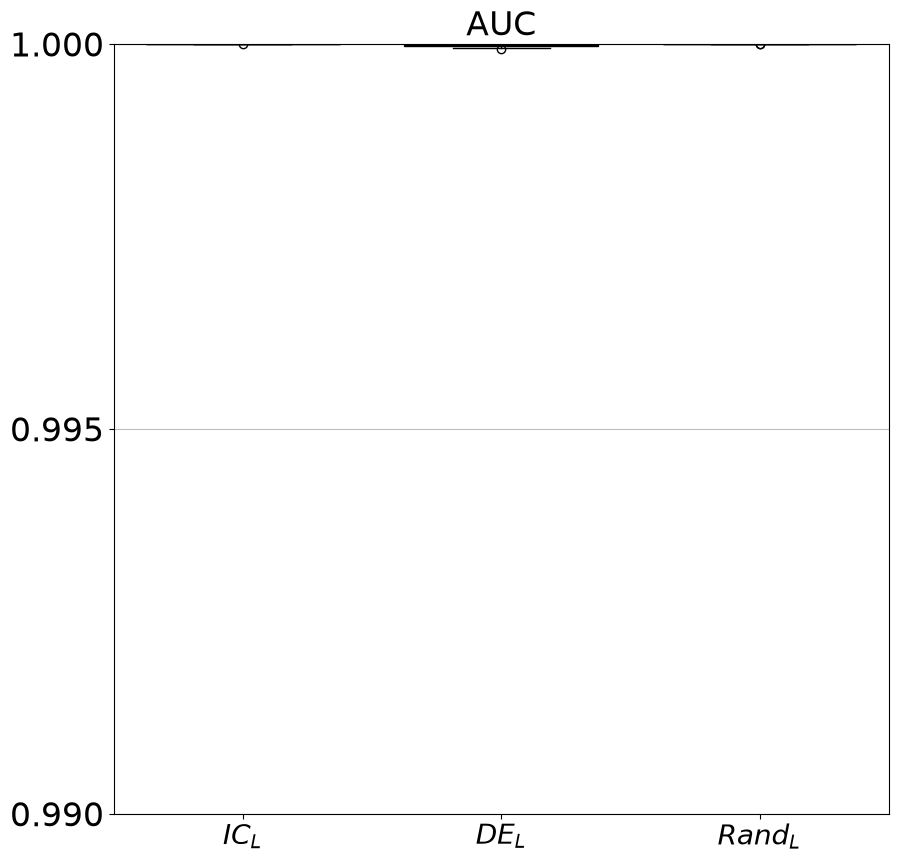

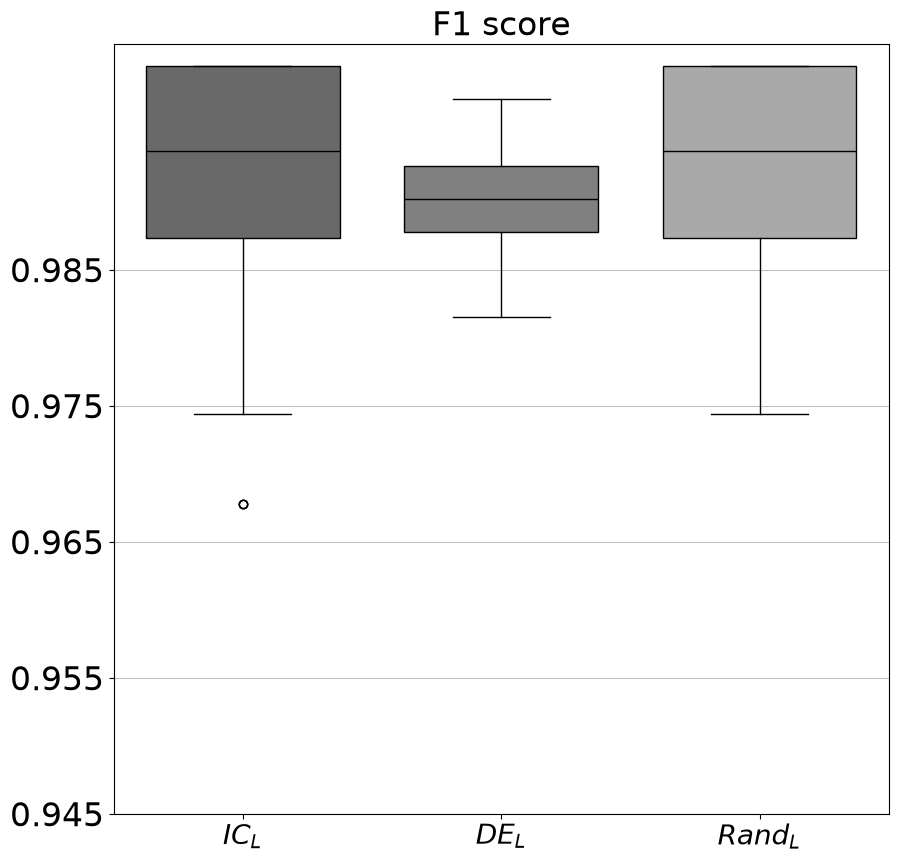

In [14]:
#Boxplots of the classification performances 
K=pd.read_csv('./Auc_acc_f1/auc_acc_f1_IC_'+str(tumor)+'.csv', index_col=0)
X=pd.read_csv('./Auc_acc_f1/auc_acc_f1_DE_'+str(tumor)+'.csv', index_col=0)
Y=pd.read_csv('./Auc_acc_f1/auc_acc_f1_random_'+str(tumor)+'.csv', index_col=0)

name_k='$IC_L$'
name_x='$DE_L$'
name_y='$Rand_L$'

what='accuracy'
fig, ax = plt.subplots(figsize=(10,10))
bp0 = ax.boxplot(K[what].values, positions=[0.1], 
                 patch_artist=True, boxprops=dict(facecolor="C3"))
for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp0[element], color='black')
for patch in bp0['boxes']:
        patch.set(facecolor='dimgrey')
bp1 = ax.boxplot(X[what].values, positions=[0.3], 
                 patch_artist=True, boxprops=dict(facecolor="C3"))
for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp1[element], color='black')
for patch in bp1['boxes']:
        patch.set(facecolor='grey')
bp2 = ax.boxplot(Y[what].values, positions=[0.5],
                 patch_artist=True, boxprops=dict(facecolor="C6"))
for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp2[element], color='black')
for patch in bp2['boxes']:
        patch.set(facecolor='darkgrey')  
ax.set_xlim(0,0.6)
ax.set_title('Accuracy', fontsize=24)
ax.yaxis.grid(True, linestyle='-', which='major', color='grey', alpha=0.5)
plt.xticks([0.1,0.3,0.5],[str(name_k),str(name_x), str(name_y)], fontsize=20)
plt.yticks(np.arange(0.985,1, step=0.005),fontsize=24)
plt.savefig('./Boxplots/boxplot_'+str(what)+'lasso_IC_DE_Random_'+str(tumor)+'.png', format='png',bbox_inches='tight',dpi=600)  

what='auc'
fig, ax = plt.subplots(figsize=(10,10))
bp0 = ax.boxplot(K[what].values, positions=[0.1], 
                 patch_artist=True, boxprops=dict(facecolor="C3"))
for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp0[element], color='black')
for patch in bp0['boxes']:
        patch.set(facecolor='dimgrey')
bp1 = ax.boxplot(X[what].values, positions=[0.3], 
                 patch_artist=True, boxprops=dict(facecolor="C3"))
for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp1[element], color='black')
for patch in bp1['boxes']:
        patch.set(facecolor='grey')
bp2 = ax.boxplot(Y[what].values, positions=[0.5],
                 patch_artist=True, boxprops=dict(facecolor="C6"))
for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp2[element], color='black')
for patch in bp2['boxes']:
        patch.set(facecolor='darkgrey') 
#ax.legend([ bp2["boxes"][0], bp1['boxes'][0]], ['N2V_all', 'Random'], loc='upper right')
ax.set_xlim(0,0.6)
ax.set_title('AUC', fontsize=24)
ax.yaxis.grid(True, linestyle='-', which='major', color='grey', alpha=0.5)
plt.xticks([0.1,0.3,0.5],[str(name_k),str(name_x), str(name_y)], fontsize=20)
plt.yticks(np.arange(0.990,1, step=0.005),fontsize=24)
plt.savefig('./Boxplots/boxplot_'+str(what)+'lasso_IC_DE_Random_'+str(tumor)+'.png', format='png',bbox_inches='tight',dpi=600)  

what='f1'
fig, ax = plt.subplots(figsize=(10,10))
bp0 = ax.boxplot(K[what].values, positions=[0.1], 
                 patch_artist=True, boxprops=dict(facecolor="C3"))
for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp0[element], color='black')
for patch in bp0['boxes']:
        patch.set(facecolor='dimgrey')
bp1 = ax.boxplot(X[what].values, positions=[0.3], 
                 patch_artist=True, boxprops=dict(facecolor="C3"))
for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp1[element], color='black')
for patch in bp1['boxes']:
        patch.set(facecolor='grey')
bp2 = ax.boxplot(Y[what].values, positions=[0.5],
                 patch_artist=True, boxprops=dict(facecolor="C6"))
for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp2[element], color='black')
for patch in bp2['boxes']:
        patch.set(facecolor='darkgrey')
ax.set_xlim(0,0.6)

ax.set_title('F1 score', fontsize=24)
ax.yaxis.grid(True, linestyle='-', which='major', color='grey', alpha=0.5)
plt.xticks([0.1,0.3,0.5],[str(name_k),str(name_x), str(name_y)], fontsize=20)
plt.yticks(np.arange(0.945,0.99, step=0.01),fontsize=24)
ax.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))
plt.savefig('./Boxplots/boxplot_'+str(what)+'lasso_IC_DE_Random_'+str(tumor)+'.png', format='png',bbox_inches='tight',dpi=600)  



